# 01 · Power-flow basics: the physics every grid AI model must respect
**Level 1 · Foundations** &nbsp;|&nbsp; Course link: *Module 2 – Computational methods for energy networks*

Before any AI model, we need the **physical model of the grid**. A *power flow* (load flow) computes, for given
consumption and generation, the **voltage at every bus** and the **current/loading of every cable and transformer**.
Every later notebook uses it: to generate training data, to label overloads, to check that an AI decision is
physically feasible.

**You will learn**
1. how to build a small low-voltage (LV) feeder in `pandapower` and solve it with Newton–Raphson,
2. what voltage limits and line loading mean, and when a cable is *overloaded*,
3. how a realistic grid (SimBench) behaves over a day with household demand and rooftop PV.

## 1. The power-flow equations
Each bus $i$ has a voltage $V_i\angle\theta_i$. The power injected at bus $i$ must equal what flows into the network
(Kirchhoff + Ohm, written with the bus admittance matrix $Y = G + jB$):

$$P_i = \sum_{j} |V_i||V_j|\left(G_{ij}\cos\theta_{ij} + B_{ij}\sin\theta_{ij}\right),\qquad
  Q_i = \sum_{j} |V_i||V_j|\left(G_{ij}\sin\theta_{ij} - B_{ij}\cos\theta_{ij}\right)$$

These equations are **non-linear**, so they are solved iteratively. **Newton–Raphson** linearises them around the
current guess $x=(\theta,|V|)$ and corrects it with the Jacobian $J$ until the mismatch is tiny:

$$J(x_k)\,\Delta x_k = -\begin{bmatrix}\Delta P(x_k)\\ \Delta Q(x_k)\end{bmatrix},\qquad x_{k+1}=x_k+\Delta x_k$$

Typical result: convergence in 3–5 iterations. Operating limits we will check:
* voltage magnitude within **0.90–1.10 p.u.** (EN 50160 for LV),
* line and transformer **loading ≤ 100 %** of their thermal rating.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
from energy_ai import simbench_grid, plot_grid, style
style()
print("pandapower", pp.__version__)

pandapower 3.5.6


## 2. Build a small LV feeder by hand
A 20 kV / 0.4 kV transformer feeds a 400 m underground cable with four houses spread along it.

In [2]:
net = pp.create_empty_network()
b_mv = pp.create_bus(net, vn_kv=20.0, name="MV grid")
b_lv = pp.create_bus(net, vn_kv=0.4, name="LV busbar")
houses = [pp.create_bus(net, vn_kv=0.4, name=f"house {k+1}") for k in range(4)]

pp.create_ext_grid(net, b_mv, vm_pu=1.0, name="slack (upstream grid)")
pp.create_transformer(net, b_mv, b_lv, std_type="0.25 MVA 20/0.4 kV", name="MV/LV transformer")
prev = b_lv
for k, b in enumerate(houses):
    pp.create_line(net, prev, b, length_km=0.1, std_type="NAYY 4x50 SE", name=f"cable {k+1}")
    pp.create_load(net, b, p_mw=0.012, q_mvar=0.003, name=f"load {k+1}")   # 12 kW, 3 kvar per house
    prev = b

pp.runpp(net, algorithm="nr")
res = net.res_bus.join(net.bus[["name"]])[["name", "vm_pu", "va_degree", "p_mw"]]
display(res.round(4))
display(net.res_line.join(net.line[["name"]])[["name", "p_from_mw", "i_ka", "loading_percent"]].round(3))
print(f"transformer loading: {net.res_trafo.loading_percent.iloc[0]:.1f} %  |  "
      f"grid losses: {1000*net.res_line.pl_mw.sum():.2f} kW")

,name,vm_pu,va_degree,p_mw
0,MV grid,1.0000,0.0000,-0.051
1,LV busbar,0.9941,-150.6365,0.000
2,house 1,0.9733,-150.4989,0.012
3,house 2,0.9576,-150.3918,0.012
4,house 3,0.9471,-150.3184,0.012
5,house 4,0.9418,-150.2811,0.012


,name,p_from_mw,i_ka,loading_percent
0,cable 1,0.050,0.075,52.672
1,cable 2,0.037,0.056,39.755
2,cable 3,0.024,0.038,26.626
3,cable 4,0.012,0.019,13.350


transformer loading: 21.0 %  |  grid losses: 2.04 kW


The voltage drops along the feeder (the last house is furthest) and the first cable carries the most current
because it supplies all four houses. Now let us **stress** the feeder: scale all loads from 0.2× to 4× and watch
the limits.

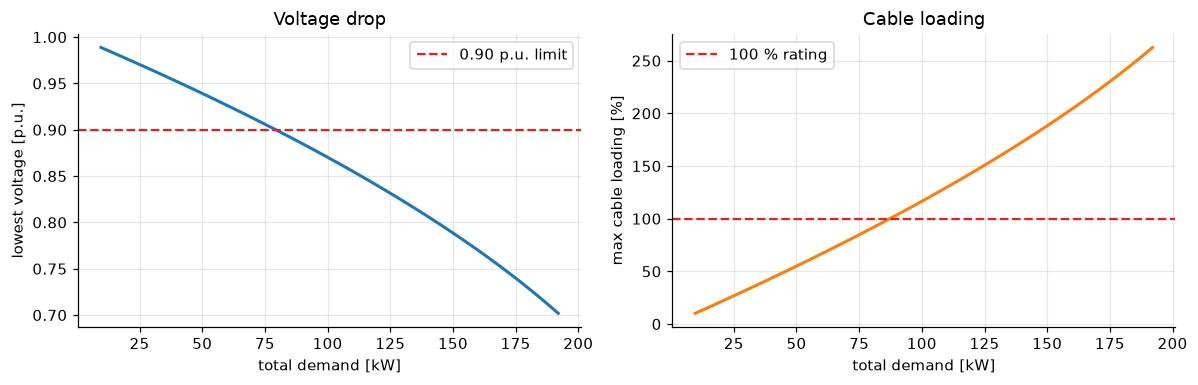

voltage limit violated above ≈ 80 kW, cable overloaded above ≈ 89 kW


In [3]:
scales = np.linspace(0.2, 4.0, 40)
vmin, lmax = [], []
base_p, base_q = net.load.p_mw.copy(), net.load.q_mvar.copy()
for s in scales:
    net.load.p_mw, net.load.q_mvar = base_p * s, base_q * s
    pp.runpp(net)
    vmin.append(net.res_bus.vm_pu.min())
    lmax.append(net.res_line.loading_percent.max())
net.load.p_mw, net.load.q_mvar = base_p, base_q

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(scales * 48, vmin, lw=2); ax[0].axhline(0.9, color="tab:red", ls="--", label="0.90 p.u. limit")
ax[0].set(xlabel="total demand [kW]", ylabel="lowest voltage [p.u.]", title="Voltage drop"); ax[0].legend()
ax[1].plot(scales * 48, lmax, lw=2, color="tab:orange"); ax[1].axhline(100, color="tab:red", ls="--", label="100 % rating")
ax[1].set(xlabel="total demand [kW]", ylabel="max cable loading [%]", title="Cable loading"); ax[1].legend()
plt.tight_layout(); plt.show()
first_v = scales[np.argmax(np.array(vmin) < 0.9)] * 48
first_l = scales[np.argmax(np.array(lmax) > 100)] * 48
print(f"voltage limit violated above ≈ {first_v:.0f} kW, cable overloaded above ≈ {first_l:.0f} kW")

**Insight:** in long rural feeders the *voltage* limit is often reached before the *thermal* limit; in short urban
feeders it is the other way round. AI models for grid operation must predict both.

## 3. A realistic grid: SimBench rural LV network
SimBench provides German benchmark grids **with a full year of 15-minute profiles** for every household and PV
system. This is the data source for many later notebooks (anomaly detection, overload prediction, congestion).

15 buses, 13 loads (households), 4 PV systems, 13 cables
profile shape: (35136, 13) → one year at 15-min resolution


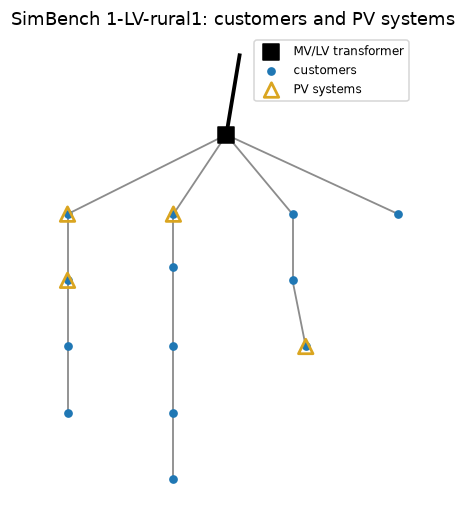

In [4]:
net, prof = simbench_grid("1-LV-rural1--0-sw")
print(f"{len(net.bus)} buses, {len(net.load)} loads (households), {len(net.sgen)} PV systems, {len(net.line)} cables")
print("profile shape:", prof[("load", "p_mw")].shape, "→ one year at 15-min resolution")

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_grid(net, ax, title="SimBench 1-LV-rural1: customers and PV systems")
plt.show()

### Time-series power flow: one summer day
For every 15-minute step we set each household's demand and each PV system's output from the profiles, solve the
power flow, and record the transformer loading and the voltage band.

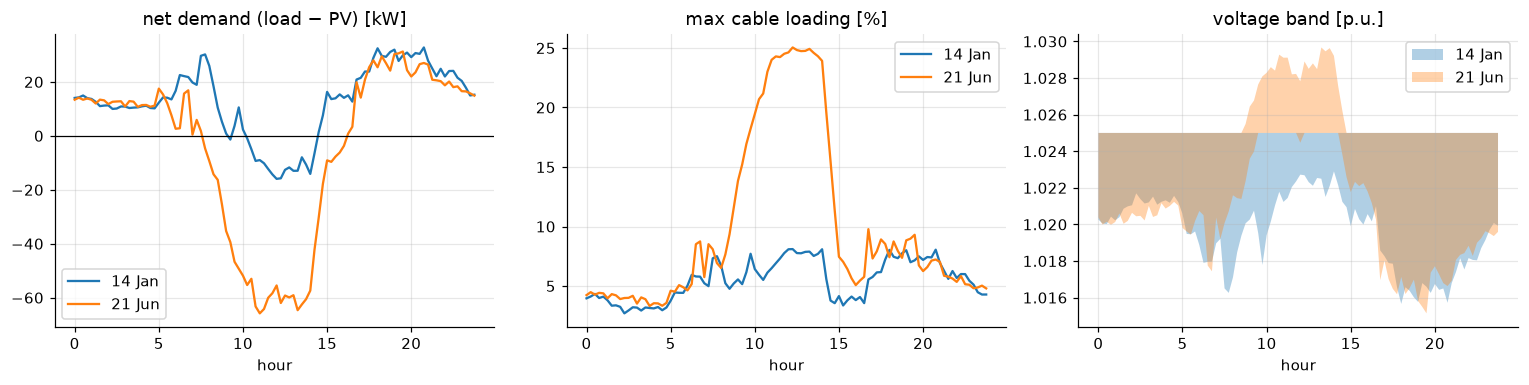

In [5]:
def daily_power_flow(net, prof, day):
    steps = prof[("load", "p_mw")].loc[day].index
    out = []
    for t in steps:
        net.load["p_mw"] = prof[("load", "p_mw")].loc[t].values
        net.load["q_mvar"] = prof[("load", "q_mvar")].loc[t].values
        net.sgen["p_mw"] = prof[("sgen", "p_mw")].loc[t].values
        pp.runpp(net)
        out.append({"time": t, "load_kw": 1000 * net.load.p_mw.sum(), "pv_kw": 1000 * net.sgen.p_mw.sum(),
                    "trafo_loading": net.res_trafo.loading_percent.iloc[0],
                    "line_max": net.res_line.loading_percent.max(),
                    "v_min": net.res_bus.vm_pu.min(), "v_max": net.res_bus.vm_pu.max()})
    return pd.DataFrame(out).set_index("time")

summer = daily_power_flow(net, prof, "2016-06-21")
winter = daily_power_flow(net, prof, "2016-01-14")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for df, lab in ((winter, "14 Jan"), (summer, "21 Jun")):
    h = df.index.hour + df.index.minute / 60
    ax[0].plot(h, df.load_kw - df.pv_kw, label=lab)
    ax[1].plot(h, df.line_max, label=lab)
    ax[2].fill_between(h, df.v_min, df.v_max, alpha=0.35, label=lab)
ax[0].set(title="net demand (load − PV) [kW]", xlabel="hour"); ax[0].axhline(0, color="k", lw=0.8)
ax[1].set(title="max cable loading [%]", xlabel="hour")
ax[2].set(title="voltage band [p.u.]", xlabel="hour")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

On the summer day, midday PV exceeds local demand: power flows **back** to the transformer (negative net demand),
the cables carry their **highest loading of the day** (reverse flow) and the voltages **rise**. The evening demand
peak gives the **lowest voltages** in both seasons. In this rural grid it is PV, not demand, that stresses the
cables most: exactly the kind of situation that AI models later have to predict and manage.

## Key takeaways
* The power flow turns demand/generation into voltages and loadings; it is the "physics engine" of grid AI.
* Limits: voltage 0.9–1.1 p.u., loading ≤ 100 %. Rural feeders hit voltage limits first, urban feeders thermal limits.
* SimBench gives realistic grids **and** a year of profiles: ideal to generate labelled data for machine learning.

**Try it yourself:** change `std_type` of the cables to `"NAYY 4x150 SE"` and repeat the stress test; or run
`daily_power_flow` for the grid `"1-LV-rural1--2-sw"` (future scenario with more PV, heat pumps and EVs).